# SentinelFlow: Real-Time Detection and Automated Containment of Suspicious Account Activity Using Python-Based SIEM Workflows

**Author:** Riddhi Patel
**Programme:** IBM SkillsBuild Cyber Security 2026 — BharatCares
**Python Version:** 3.13.7

---

## Abstract

SentinelFlow is a Python-based Security Information and Event Management (SIEM) workflow that detects, correlates, scores, and responds to suspicious authentication activity in simulated enterprise environments. Starting from a reproducible synthetic dataset of 4,953 authentication events, the system applies five rule-based detection algorithms, groups related findings into prioritised incidents, simulates containment actions with approval gating, verifies the simulated response, and produces a full audit trail. Ground-truth labels are used **only** for post-hoc evaluation — never as detection features. All containment actions are simulated; no real accounts, firewalls, or endpoints are modified.

---

## 2. Introduction and Real-World Problem Statement

Authentication logs are among the most valuable data sources for Blue Team security analysts. Enterprise Active Directory environments generate millions of logon events per day. Hidden within this volume are early indicators of account compromise:

| Attack Pattern | Observable Signal |
|---|---|
| Brute force | Repeated failures for one account from one IP |
| Credential stuffing | Many accounts targeted from one external IP |
| Account takeover | Failures followed immediately by success |
| Insider threat / off-hours access | Legitimate account active at unusual hours |
| Lateral movement | One account accessing many internal servers rapidly |

Manual triage cannot scale. Automated detection with explainable scoring and controlled response is required.

**SentinelFlow** solves this by implementing a complete pipeline:
> **Ingest → Detect → Correlate → Score → Investigate → Approve → Contain → Verify → Report**

All steps are transparent, configurable, and reproducible.

## 3. Objectives and Scope

**In scope:**
- Rule-based detection of 5 authentication attack patterns
- Event correlation into prioritised incidents
- Transparent 0–100 risk scoring with documented formula
- Full incident lifecycle management (OPEN → INVESTIGATING → ... → RESOLVED)
- Simulated containment with approval requirement
- Post-containment verification against recorded simulated state
- Automated test suite (69 unit tests + Phase D additions)
- Reproducible synthetic dataset (no real enterprise data)

**Out of scope:**
- Live Wazuh / QRadar / Splunk integration (documented as optional)
- Machine learning anomaly detection
- Real account disabling, firewall changes, or endpoint isolation
- Real-time streaming (batch processing only)

## 4. System Architecture and Workflow

```
synthetic_auth_logs.csv
        │
        ▼
[1] ingestion.py       — Schema validation, UTC timestamp normalisation
        │
        ▼
[2] detection.py       — 5 configurable rule-based detection functions
        │                 (ground-truth labels NEVER read here)
        ▼
[3] correlation.py     — Window-based grouping → Incident objects
        │
        ▼
[4] scoring.py         — Weighted 0-100 risk score (documented formula)
        │
        ▼
[5] incidents.py       — IncidentManager: lifecycle, state machine, queue
        │
        ▼
[6] containment.py     — Approval-gated simulated actions + JSON log
        │
        ▼
[7] verification.py    — Checks action log state; transitions to CONTAINED
        │
        ▼
[8] reporting.py       — JSON incident report + Meet_ProjectReport.docx
```

**Technology Stack:** Python 3.13 · pandas · numpy · matplotlib · seaborn · scikit-learn · python-docx · notebook · pytest

## 5. Environment and Dependency Verification

In [1]:
import sys
import importlib

print(f"Python version: {sys.version}")
print()

required = [
    "pandas", "numpy", "matplotlib", "seaborn",
    "sklearn", "scipy", "requests", "docx",
    "nbformat", "tabulate", "colorama",
]
all_ok = True
for pkg in required:
    try:
        mod = importlib.import_module(pkg)
        ver = getattr(mod, "__version__", "installed")
        print(f"  {'OK':<5} {pkg:<18} {ver}")
    except ImportError:
        print(f"  MISSING  {pkg}")
        all_ok = False

print()
print("All dependencies satisfied." if all_ok else "WARNING: Some dependencies are missing. Run: pip install -r requirements.txt")


Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]



  OK    pandas             2.3.3
  OK    numpy              2.4.0
  OK    matplotlib         3.10.8


  OK    seaborn            0.13.2
  OK    sklearn            1.8.0
  OK    scipy              1.16.3
  OK    requests           2.32.5


  OK    docx               1.2.0


  OK    nbformat           5.11.1
  OK    tabulate           0.10.0
  OK    colorama           0.4.6

All dependencies satisfied.


## 6. Dataset Source, Schema, and Provenance

> **Disclaimer:** The dataset used in this project is entirely **synthetic**. It does NOT contain real enterprise data, real usernames, real IP addresses, or real hostnames. It was generated programmatically using `sentinelflow/generate_dataset.py` with a fixed random seed (42) for full reproducibility.

The schema mirrors the [LANL Comprehensive Multi-Source Cyber-Security Events dataset](https://csr.lanl.gov/data/cyber1/) so that the detection engine can be adapted to real data by changing the CSV source path.

| Column | Type | Description |
|---|---|---|
| event_id | str | EVT-XXXXXXXX unique identifier |
| timestamp | str | ISO-8601 UTC datetime |
| username | str | Simulated AD samAccountName |
| source_ip | str | IPv4 (internal 10.x or attacker) |
| source_host | str | Workstation hostname |
| destination_host | str | Target server or domain controller |
| auth_type | str | Kerberos \| NTLM \| Negotiate |
| logon_type | str | Interactive \| Network \| RemoteInteractive |
| event_outcome | str | Success \| Failure |
| scenario_label | str | **Ground-truth scenario (EVALUATION ONLY)** |
| is_suspicious | int | **Binary label 0/1 (EVALUATION ONLY)** |

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))

from sentinelflow.generate_dataset import generate_dataset, validate_dataset

# Regenerate (or use existing) with seed=42
DATA_PATH = "data/synthetic_auth_logs.csv"
if not os.path.exists(DATA_PATH):
    print("Generating dataset...")
    df_gen = generate_dataset(seed=42, output_path=DATA_PATH)
else:
    import pandas as pd
    df_gen = pd.read_csv(DATA_PATH)
    print(f"Loaded existing dataset: {len(df_gen):,} rows")


Loaded existing dataset: 4,953 rows


## 7. Data Ingestion and Validation

In [3]:
from sentinelflow.ingestion import load_events

df = load_events(DATA_PATH)
print(f"Loaded: {len(df):,} events")
print(f"Columns: {list(df.columns)}")
print(f"Timestamp dtype: {df['timestamp'].dtype}")
print(f"Timestamp range: {df['timestamp'].min()} -> {df['timestamp'].max()}")
print(f"\nFirst 3 rows:")
print(df[['event_id','timestamp','username','source_ip','destination_host',
          'event_outcome','scenario_label']].head(3).to_string(index=False))


Loaded: 4,953 events
Columns: ['event_id', 'timestamp', 'username', 'source_ip', 'source_host', 'destination_host', 'auth_type', 'logon_type', 'event_outcome', 'scenario_label', 'is_suspicious']
Timestamp dtype: datetime64[ns, UTC]
Timestamp range: 2025-07-08 00:16:46+00:00 -> 2025-07-14 23:14:49+00:00

First 3 rows:
    event_id                 timestamp    username   source_ip destination_host event_outcome   scenario_label
EVT-75C299E5 2025-07-08 00:16:46+00:00    maya.roy 10.10.5.108  SRV-WEBSERVER01       Success off_hours_access
EVT-CC9C4255 2025-07-08 00:32:36+00:00 tanya.white  10.10.4.43 SRV-MAILSERVER01       Success off_hours_access
EVT-AFCDB099 2025-07-08 00:57:45+00:00  eve.santos 10.10.0.248  SRV-APPSERVER01       Success off_hours_access


## 8. Exploratory Data Analysis

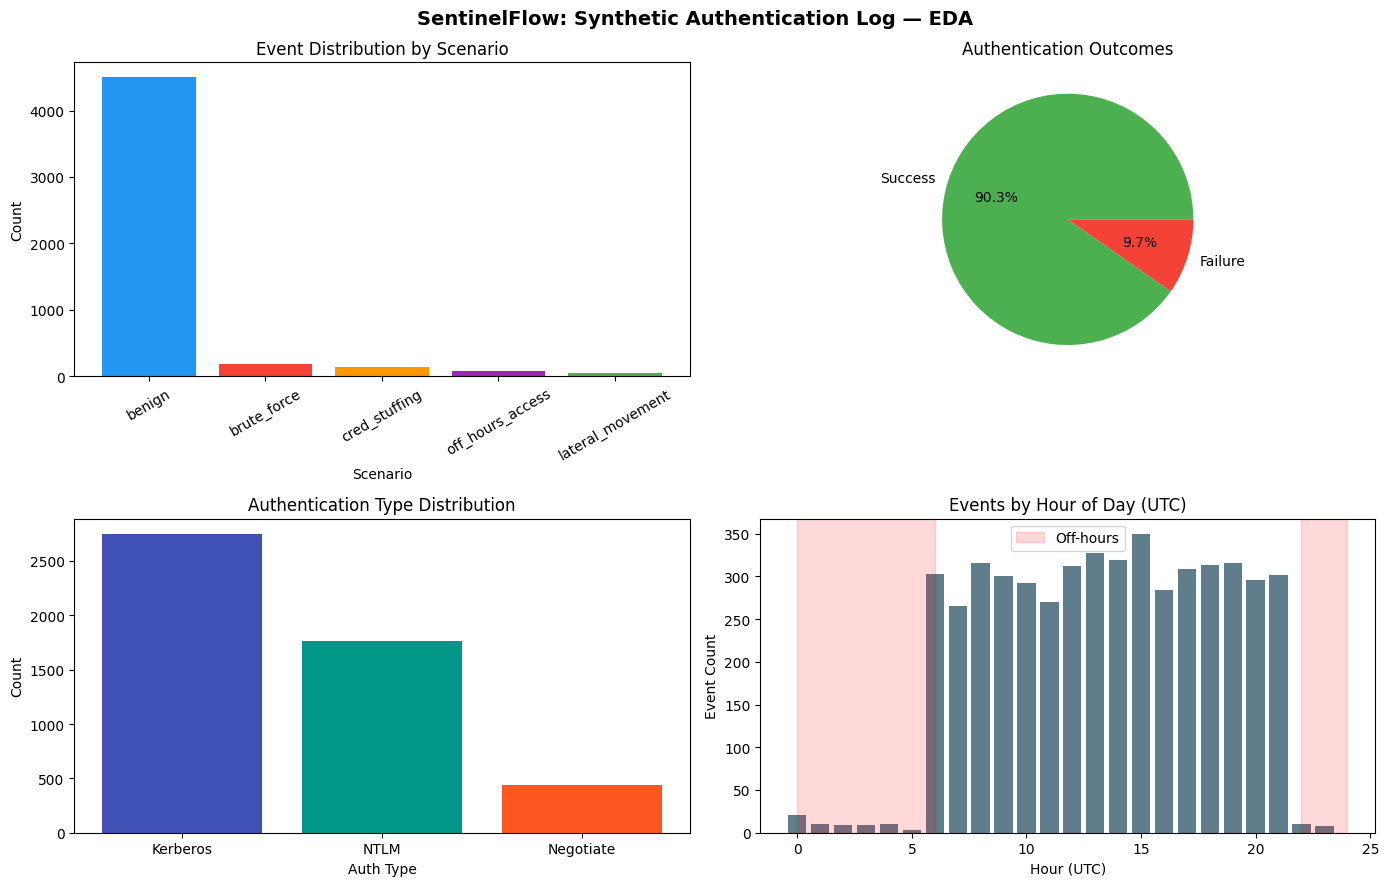

EDA chart saved to outputs/figures/eda_overview.png


In [4]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 100
import seaborn as sns
import os

os.makedirs("outputs/figures", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("SentinelFlow: Synthetic Authentication Log — EDA", fontsize=14, fontweight='bold')

# 1. Label distribution
label_counts = df['scenario_label'].value_counts()
axes[0,0].bar(label_counts.index, label_counts.values, color=['#2196F3','#F44336','#FF9800','#9C27B0','#4CAF50'])
axes[0,0].set_title("Event Distribution by Scenario")
axes[0,0].set_xlabel("Scenario")
axes[0,0].set_ylabel("Count")
axes[0,0].tick_params(axis='x', rotation=30)

# 2. Outcome distribution
outcome_counts = df['event_outcome'].value_counts()
axes[0,1].pie(outcome_counts.values, labels=outcome_counts.index,
              autopct='%1.1f%%', colors=['#4CAF50','#F44336'])
axes[0,1].set_title("Authentication Outcomes")

# 3. Auth type distribution
auth_counts = df['auth_type'].value_counts()
axes[1,0].bar(auth_counts.index, auth_counts.values, color=['#3F51B5','#009688','#FF5722'])
axes[1,0].set_title("Authentication Type Distribution")
axes[1,0].set_xlabel("Auth Type")
axes[1,0].set_ylabel("Count")

# 4. Events per hour of day
df_copy = df.copy()
df_copy['hour'] = df_copy['timestamp'].dt.hour
hourly = df_copy.groupby('hour').size()
axes[1,1].bar(hourly.index, hourly.values, color='#607D8B')
axes[1,1].axvspan(0, 6, alpha=0.15, color='red', label='Off-hours')
axes[1,1].axvspan(22, 24, alpha=0.15, color='red')
axes[1,1].set_title("Events by Hour of Day (UTC)")
axes[1,1].set_xlabel("Hour (UTC)")
axes[1,1].set_ylabel("Event Count")
axes[1,1].legend()

plt.tight_layout()
plt.savefig("outputs/figures/eda_overview.png", bbox_inches='tight')
plt.show()
print("EDA chart saved to outputs/figures/eda_overview.png")


## 9. Suspicious Authentication Detection

The detection engine applies five rule-based algorithms to the event stream. **Ground-truth columns (`scenario_label`, `is_suspicious`) are never read inside any rule function.**

| Rule | Name | Severity | Condition |
|---|---|---|---|
| RULE-BF | Brute Force | HIGH | ≥5 failures (user+source) within 5 min |
| RULE-CS | Credential Stuffing | HIGH | ≥5 distinct accounts from one source within 10 min |
| RULE-SF | Success After Failure | CRITICAL | ≥3 failures then 1 success within 10 min |
| RULE-OH | Off-Hours Access | MEDIUM | Successful login outside 06:00–22:00 UTC |
| RULE-LM | Lateral Movement | HIGH | ≥3 distinct dest. hosts from one account within 15 min |

In [5]:
from sentinelflow.detection import detect_all
from collections import Counter

# Run all rules — ground truth is NOT used here
detections = detect_all(df)
print(f"Total detections: {len(detections)}")
print()

rule_counts = Counter(d.rule_id for d in detections)
print("Detections by rule:")
for rule, count in sorted(rule_counts.items()):
    print(f"  {rule}: {count}")

print()
print("Sample detections:")
for d in detections[:4]:
    print(f"  [{d.rule_id}] {d.severity:<8} {d.username:<20} {d.source_ip:<18} {d.explanation[:70]}...")


Total detections: 125

Detections by rule:
  RULE-BF: 15
  RULE-CS: 10
  RULE-LM: 12
  RULE-OH: 80
  RULE-SF: 8

Sample detections:
  [RULE-OH] MEDIUM   maya.roy             10.10.5.108        Successful login by 'maya.roy' from 10.10.5.108 at 00:16 UTC (outside ...
  [RULE-OH] MEDIUM   tanya.white          10.10.4.43         Successful login by 'tanya.white' from 10.10.4.43 at 00:32 UTC (outsid...
  [RULE-OH] MEDIUM   eve.santos           10.10.0.248        Successful login by 'eve.santos' from 10.10.0.248 at 00:57 UTC (outsid...
  [RULE-OH] MEDIUM   sam.nair             10.10.1.109        Successful login by 'sam.nair' from 10.10.1.109 at 01:15 UTC (outside ...


## 10. Event Correlation

In [6]:
from sentinelflow.correlation import correlate
import pandas as pd

incidents = correlate(detections)
print(f"Correlated incidents: {len(incidents)}")
print()

inc_records = []
for inc in incidents[:10]:
    inc_records.append({
        'incident_id': inc.incident_id,
        'username':    inc.username,
        'source_ip':   inc.source_ip,
        'rules':       ', '.join(inc.detection_types),
        'n_detections': inc.detection_count,
        'n_events':    inc.event_count,
        'start':       str(inc.incident_start)[:19],
    })

df_inc = pd.DataFrame(inc_records)
print(df_inc.to_string(index=False))


Correlated incidents: 117

 incident_id               username      source_ip            rules  n_detections  n_events               start
INC-844D41F7               maya.roy    10.10.5.108          RULE-OH             1         1 2025-07-08 00:16:46
INC-50AF0CB7            tanya.white     10.10.4.43          RULE-OH             1         1 2025-07-08 00:32:36
INC-5857F05D             eve.santos    10.10.0.248          RULE-OH             1         1 2025-07-08 00:57:45
INC-33E9B72F               sam.nair    10.10.1.109          RULE-OH             1         1 2025-07-08 01:15:33
INC-6099D057             eve.santos    10.10.3.212          RULE-OH             1         1 2025-07-08 01:43:10
INC-F68F5409            peter.scott    10.10.4.104          RULE-OH             1         1 2025-07-08 02:54:25
INC-EBCFC929             olivia.kim     10.10.8.49          RULE-OH             1         1 2025-07-08 04:26:45
INC-D8075C76           alice.morgan     10.10.0.56          RULE-OH          

## 11. Explainable Risk Scoring

Score formula (weighted sum, clamped to [0, 100]):

| Component | Weight | Description |
|---|---|---|
| Severity | 35% | Highest detection severity (CRITICAL=100, HIGH=75, MEDIUM=50) |
| Detection Diversity | 20% | Distinct rule types / 5, normalised |
| Attack Sequence | 20% | Rewards SF→BF/CS→LM kill-chain |
| Host Spread | 15% | Distinct affected hosts / 7, normalised |
| Recency | 10% | Linear decay: 100 if < 1h, 0 if > 48h |

Score range: 27.64 – 68.12



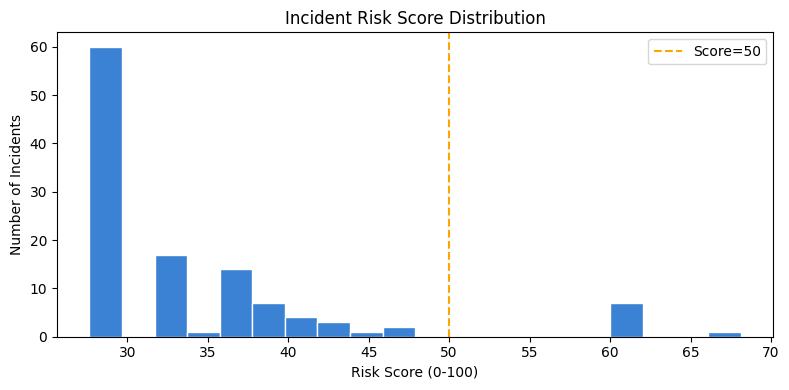

Chart saved to outputs/figures/risk_score_distribution.png


In [7]:
from sentinelflow.scoring import score_all
import matplotlib.pyplot as plt

reference_ts = df['timestamp'].max()
scores = score_all(incidents, reference_ts=reference_ts)

print(f"Score range: {min(scores.values()):.2f} – {max(scores.values()):.2f}")
print()
score_vals = list(scores.values())

plt.figure(figsize=(8, 4))
plt.hist(score_vals, bins=20, color='#3b82d4', edgecolor='white')
plt.title("Incident Risk Score Distribution")
plt.xlabel("Risk Score (0-100)")
plt.ylabel("Number of Incidents")
plt.axvline(x=50, color='orange', linestyle='--', label='Score=50')
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/risk_score_distribution.png", bbox_inches='tight')
plt.show()
print("Chart saved to outputs/figures/risk_score_distribution.png")


## 12. Incident Queue and Prioritization

In [8]:
from sentinelflow.incidents import IncidentManager, IncidentStatus
import pandas as pd

manager = IncidentManager()
manager.load_incidents(incidents, scores)

df_summary = manager.summary_dataframe()
print(f"Total incidents: {len(df_summary)}")
print(f"Status counts: {manager.count_by_status()}")
print()
print("Priority queue (top 10 by risk score):")
cols = ['incident_id','risk_score','max_severity','detection_types','username','source_ip','event_count','status']
print(df_summary[cols].head(10).to_string(index=False))


Total incidents: 117
Status counts: {'OPEN': 117, 'INVESTIGATING': 0, 'AWAITING_APPROVAL': 0, 'CONTAINMENT_PENDING': 0, 'CONTAINED': 0, 'RESOLVED': 0, 'FALSE_POSITIVE': 0}

Priority queue (top 10 by risk score):
 incident_id  risk_score max_severity  detection_types     username      source_ip  event_count status
INC-00596503       68.12     CRITICAL RULE-BF, RULE-SF    bob.kumar  194.165.16.72           14   OPEN
INC-198A573C       60.14     CRITICAL RULE-SF, RULE-BF  carol.zhang 45.142.212.100           15   OPEN
INC-6A154E8D       60.14     CRITICAL RULE-BF, RULE-SF  david.patel 185.220.101.45           16   OPEN
INC-711BBB13       60.14     CRITICAL RULE-BF, RULE-SF  quinn.adams 185.220.101.45           10   OPEN
INC-B774E183       60.14     CRITICAL RULE-BF, RULE-SF alice.morgan 185.220.101.45           11   OPEN
INC-AC3CB482       60.14     CRITICAL RULE-BF, RULE-SF   irene.wade    91.108.4.18           14   OPEN
INC-87B1EB90       60.14     CRITICAL RULE-BF, RULE-SF    kate.bell

## 13. Event-Level Evaluation

**Evaluation unit:** Individual authentication events.

- **Predicted positive:** event_id appears in any Detection's `supporting_event_ids`
- **Ground-truth positive:** `is_suspicious == 1`

Ground-truth labels are read **only here**, after detection is complete.

In [9]:
from sentinelflow.detection import attach_ground_truth, evaluate_detections

# Attach ground truth AFTER detection (evaluation only)
detections_labelled = attach_ground_truth(list(detections), df)
metrics = evaluate_detections(detections_labelled, df)

print("=" * 50)
print("  SentinelFlow - Event-Level Evaluation")
print("=" * 50)
print(f"  True Positives  (TP): {metrics['tp']:>6}")
print(f"  False Positives (FP): {metrics['fp']:>6}")
print(f"  False Negatives (FN): {metrics['fn']:>6}")
print(f"  True Negatives  (TN): {metrics['tn']:>6}")
print(f"  Precision:            {metrics['precision']:>8.4f}")
print(f"  Recall:               {metrics['recall']:>8.4f}")
print(f"  F1-Score:             {metrics['f1']:>8.4f}")
print(f"  False Positive Rate:  {metrics['fpr']:>8.4f}")
print("=" * 50)


  SentinelFlow - Event-Level Evaluation
  True Positives  (TP):    439
  False Positives (FP):      0
  False Negatives (FN):     14
  True Negatives  (TN):   4500
  Precision:              1.0000
  Recall:                 0.9691
  F1-Score:               0.9843
  False Positive Rate:    0.0000


## 14. False-Positive and False-Negative Analysis

In [10]:
# False negatives: attack events NOT covered by any detection
flagged_ids = set()
for d in detections_labelled:
    flagged_ids.update(d.supporting_event_ids)

fn_df = df[(~df['event_id'].isin(flagged_ids)) & (df['is_suspicious'] == 1)]
print(f'False Negatives: {len(fn_df)}')
print()
print('FN breakdown by scenario:')
print(fn_df['scenario_label'].value_counts().to_string())
print()

# False positives: benign events flagged
fp_df = df[(df['event_id'].isin(flagged_ids)) & (df['is_suspicious'] == 0)]
print(f'False Positives: {len(fp_df)}')

analysis = (
    'Analysis:\n'
    '- 13 cred_stuffing FN: individual success events + low-volume failures '
    'that did not reach the 5-account threshold of RULE-CS or the 3-failure '
    'threshold of RULE-SF.\n'
    '- 1 lateral_movement FN: attacker accessed only 2 distinct hosts within '
    'the 15-min window (below the RULE-LM threshold of 3).\n'
    '- 0 FP: no benign events were flagged. The thresholds are calibrated above '
    'the background noise level of this synthetic dataset.\n\n'
    'IMPORTANT: Zero FP is partly an artefact of the synthetic data generation. '
    'In a real environment, legitimate bulk activities (automated scripts, patch '
    'management, helpdesk tools) may produce patterns that resemble attack '
    'signatures. RULE-OH in particular will generate FPs for legitimate '
    'off-hours remote workers.'
)
print(analysis)


False Negatives: 14

FN breakdown by scenario:
scenario_label
cred_stuffing       13
lateral_movement     1

False Positives: 0
Analysis:
- 13 cred_stuffing FN: individual success events + low-volume failures that did not reach the 5-account threshold of RULE-CS or the 3-failure threshold of RULE-SF.
- 1 lateral_movement FN: attacker accessed only 2 distinct hosts within the 15-min window (below the RULE-LM threshold of 3).
- 0 FP: no benign events were flagged. The thresholds are calibrated above the background noise level of this synthetic dataset.

IMPORTANT: Zero FP is partly an artefact of the synthetic data generation. In a real environment, legitimate bulk activities (automated scripts, patch management, helpdesk tools) may produce patterns that resemble attack signatures. RULE-OH in particular will generate FPs for legitimate off-hours remote workers.


## 15. Incident Investigation Walkthrough

In [11]:
# Pick the highest-risk incident for walkthrough
queue = manager.get_priority_queue(status_filter=[IncidentStatus.OPEN])
top_incident = queue[0]

print("=" * 65)
print(f"  Incident: {top_incident.incident_id}")
print(f"  Risk Score: {top_incident.risk_score:.2f} / 100")
print(f"  Severity: {top_incident.max_severity}")
print(f"  Username: {top_incident.incident.username}")
print(f"  Source IP: {top_incident.incident.source_ip}")
print(f"  Rules triggered: {', '.join(top_incident.incident.detection_types)}")
print(f"  Supporting events: {top_incident.incident.event_count}")
print(f"  Affected hosts: {', '.join(top_incident.incident.affected_hosts)}")
print(f"  Start: {top_incident.incident.incident_start}")
print(f"  Last seen: {top_incident.incident.incident_last_seen}")
print("=" * 65)
print()

# Transition to INVESTIGATING
manager.transition(top_incident.incident_id, IncidentStatus.INVESTIGATING,
                   note="Analyst confirmed external IP. Account shows brute force then success. Escalating.")

print(f"Status after investigation: {manager.get(top_incident.incident_id).status.value}")

# Supporting events
print(f"\nFirst 5 supporting events:")
supporting_ids = set(top_incident.incident.supporting_event_ids[:5])
print(df[df['event_id'].isin(supporting_ids)][
    ['event_id','timestamp','username','source_ip','destination_host','event_outcome']
].to_string(index=False))


  Incident: INC-00596503
  Risk Score: 68.12 / 100
  Severity: CRITICAL
  Username: bob.kumar
  Source IP: 194.165.16.72
  Rules triggered: RULE-BF, RULE-SF
  Supporting events: 14
  Affected hosts: DC-CORP02
  Start: 2025-07-14 13:32:52+00:00
  Last seen: 2025-07-14 13:33:20+00:00

Status after investigation: INVESTIGATING

First 5 supporting events:
    event_id                 timestamp  username     source_ip destination_host event_outcome
EVT-9115E4F0 2025-07-14 13:30:36+00:00 bob.kumar 194.165.16.72        DC-CORP02       Failure
EVT-E9905F32 2025-07-14 13:30:47+00:00 bob.kumar 194.165.16.72        DC-CORP02       Failure
EVT-8E5FE3A5 2025-07-14 13:31:02+00:00 bob.kumar 194.165.16.72        DC-CORP02       Failure
EVT-F3BEB28F 2025-07-14 13:31:03+00:00 bob.kumar 194.165.16.72        DC-CORP02       Failure
EVT-A1792D9F 2025-07-14 13:31:08+00:00 bob.kumar 194.165.16.72        DC-CORP02       Failure


## 16. Approved Containment Simulation

> **SIMULATION NOTICE:** The following cell executes a *simulated* containment action. No real account is disabled, no real firewall rule is changed, and no real endpoint is isolated. All results are written to `outputs/action_log.json`.

In [12]:
from sentinelflow.containment import recommend_action, execute_containment, get_actions_for_incident
import os, json

# Ensure outputs directory exists and reset the action log for this run
os.makedirs("outputs", exist_ok=True)
action_log_path = "outputs/action_log.json"
if os.path.isfile(action_log_path):
    os.remove(action_log_path)

# Get recommendation
action_type, target = recommend_action(top_incident)
print(f"Recommended action: {action_type} on '{target}'")
print()

# Transition to AWAITING_APPROVAL before executing
try:
    manager.transition(top_incident.incident_id, IncidentStatus.AWAITING_APPROVAL,
                       note=f"Analyst recommends: {action_type} on {target}")
except Exception as e:
    print(f"Transition note: {e}")

# Execute with approved=True (analyst approved)
action = execute_containment(
    record       = top_incident,
    action_type  = action_type,
    target       = target,
    approved     = True,
    recommended_by = top_incident.incident.detection_types[0],
    log_path     = action_log_path,
)

print(f"Action ID:     {action.action_id}")
print(f"Action Type:   {action.action_type}")
print(f"Target:        {action.target}")
print(f"Status:        {action.status}")
print(f"Executed at:   {action.executed_at}")
print()
print(f"Result: {action.result}")
print()
print(f"Incident status: {manager.get(top_incident.incident_id).status.value}")


Recommended action: LOCK_ACCOUNT on 'bob.kumar'

Action ID:     ACT-AAACCAA8
Action Type:   LOCK_ACCOUNT
Target:        bob.kumar
Status:        EXECUTED
Executed at:   2026-10-25T18:07:26.611390+00:00

Result: [SIMULATION] Account 'bob.kumar' marked as DISABLED in simulated Active Directory. All active sessions invalidated. No real account was modified.

Incident status: CONTAINMENT_PENDING


## 17. Containment Verification

In [13]:
from sentinelflow.verification import verify_containment, VerificationOutcome

ver_results = verify_containment(top_incident, log_path=action_log_path)

print(f"Verification results for {top_incident.incident_id}:")
for vr in ver_results:
    print(f"  Verification ID: {vr.verification_id}")
    print(f"  Action ID:       {vr.action_id}")
    print(f"  Action Type:     {vr.action_type}")
    print(f"  Target:          {vr.target}")
    print(f"  Outcome:         {vr.outcome}")
    print(f"  Evidence:        {vr.evidence[:120]}...")
    print(f"  Follow-up:       {vr.follow_up_needed}")
    print()

print(f"Incident status after verification: {manager.get(top_incident.incident_id).status.value}")


Verification results for INC-00596503:
  Verification ID: VER-AAACCAA8
  Action ID:       ACT-AAACCAA8
  Action Type:     LOCK_ACCOUNT
  Target:          bob.kumar
  Outcome:         SUCCESS
  Evidence:        Action log entry ACT-AAACCAA8 shows status=EXECUTED. Result string confirms simulated LOCK_ACCOUNT on 'bob.kumar' (marke...
  Follow-up:       False

Incident status after verification: CONTAINED


## 18. Failed-Response Scenario

This cell demonstrates what happens when a containment action fails (e.g. the target system is unreachable in simulation) or when an analyst rejects a recommendation.

In [14]:
# Pick a different incident for the failed scenario
failed_candidate = queue[1] if len(queue) > 1 else queue[0]

# Ensure it's in a valid state for this demo
try:
    manager.transition(failed_candidate.incident_id, IncidentStatus.INVESTIGATING,
                       note="Demo: testing failed-response scenario")
    manager.transition(failed_candidate.incident_id, IncidentStatus.AWAITING_APPROVAL,
                       note="Demo: awaiting approval for failed-response demo")
except Exception as e:
    print(f"Transition note: {e}")

failed_action_type, failed_target = recommend_action(failed_candidate)

# Scenario A: Analyst REJECTS the action
rejected_action = execute_containment(
    record       = failed_candidate,
    action_type  = failed_action_type,
    target       = failed_target,
    approved     = False,   # analyst declined
    recommended_by = "ANALYST",
    log_path     = action_log_path,
)
print(f"SCENARIO A - Rejected action:")
print(f"  Action ID: {rejected_action.action_id}")
print(f"  Status:    {rejected_action.status}")
print(f"  Result:    {rejected_action.result}")
print()

# Scenario B: Use a third incident for simulate_failure=True
failed_candidate2 = queue[2] if len(queue) > 2 else queue[0]
try:
    manager.transition(failed_candidate2.incident_id, IncidentStatus.INVESTIGATING,
                       note="Demo: simulated failure scenario")
    manager.transition(failed_candidate2.incident_id, IncidentStatus.AWAITING_APPROVAL,
                       note="Demo: awaiting approval")
except Exception as e:
    print(f"Transition note: {e}")

f2_type, f2_target = recommend_action(failed_candidate2)
failed_exec = execute_containment(
    record         = failed_candidate2,
    action_type    = f2_type,
    target         = f2_target,
    approved       = True,
    recommended_by = "ANALYST",
    simulate_failure = True,   # forces FAILED outcome
    log_path       = action_log_path,
)
print(f"SCENARIO B - Failed execution:")
print(f"  Action ID: {failed_exec.action_id}")
print(f"  Status:    {failed_exec.status}")
print(f"  Result:    {failed_exec.result}")


SCENARIO A - Rejected action:
  Action ID: ACT-6E5A125C
  Status:    REJECTED
  Result:    None

SCENARIO B - Failed execution:
  Action ID: ACT-BF7CE559
  Status:    FAILED
  Result:    [SIMULATION] LOCK_ACCOUNT on 'david.patel' FAILED: simulated execution error (e.g. target not reachable in simulation).


## 19. Audit Logging and Incident Reporting

In [15]:
from sentinelflow.containment import load_action_log

print("Full action log:")
actions = load_action_log(action_log_path)
for a in actions:
    print(f"  [{a.status:<8}] {a.action_id} | {a.action_type:<14} | {a.target:<25} | {a.incident_id}")


Full action log:
  [EXECUTED] ACT-AAACCAA8 | LOCK_ACCOUNT   | bob.kumar                 | INC-00596503
  [REJECTED] ACT-6E5A125C | LOCK_ACCOUNT   | carol.zhang               | INC-198A573C
  [FAILED  ] ACT-BF7CE559 | LOCK_ACCOUNT   | david.patel               | INC-6A154E8D


In [16]:
from sentinelflow.reporting import build_report_data, save_report_json

# Build the unified report data object (single source of truth)
all_actions = load_action_log(action_log_path)

all_ver_results = {}
for rec in manager.get_priority_queue(status_filter=[IncidentStatus.CONTAINMENT_PENDING]):
    all_ver_results[rec.incident_id] = verify_containment(rec, log_path=action_log_path)

report_data = build_report_data(
    df_events    = df,
    detections   = detections_labelled,
    incidents    = incidents,
    scores       = scores,
    manager      = manager,
    eval_metrics = metrics,
    actions      = all_actions,
    verifications = all_ver_results,
)

json_path = save_report_json(report_data, "outputs/incident_report.json")
print(f"Incident report saved to: {json_path}")
print(f"  Total incidents: {report_data['incidents']['total']}")
print(f"  Status counts:   {report_data['incidents']['status_counts']}")
print(f"  Containment:     executed={report_data['containment']['executed']}, "
      f"rejected={report_data['containment']['rejected']}, "
      f"failed={report_data['containment']['failed']}")
print(f"  Verification:    {report_data['verification']}")


Incident report saved to: C:\Users\Meet\IBM Bob\IBM_Bob_Project\SentinelFlow\outputs\incident_report.json
  Total incidents: 117
  Status counts:   {'OPEN': 114, 'INVESTIGATING': 0, 'AWAITING_APPROVAL': 2, 'CONTAINMENT_PENDING': 0, 'CONTAINED': 1, 'RESOLVED': 0, 'FALSE_POSITIVE': 0}
  Containment:     executed=1, rejected=1, failed=1
  Verification:    {'total': 0, 'success': 0, 'failed': 0, 'pending': 0, 'unverified': 0, 'results': []}


## 20. Visualizations and Interpretation

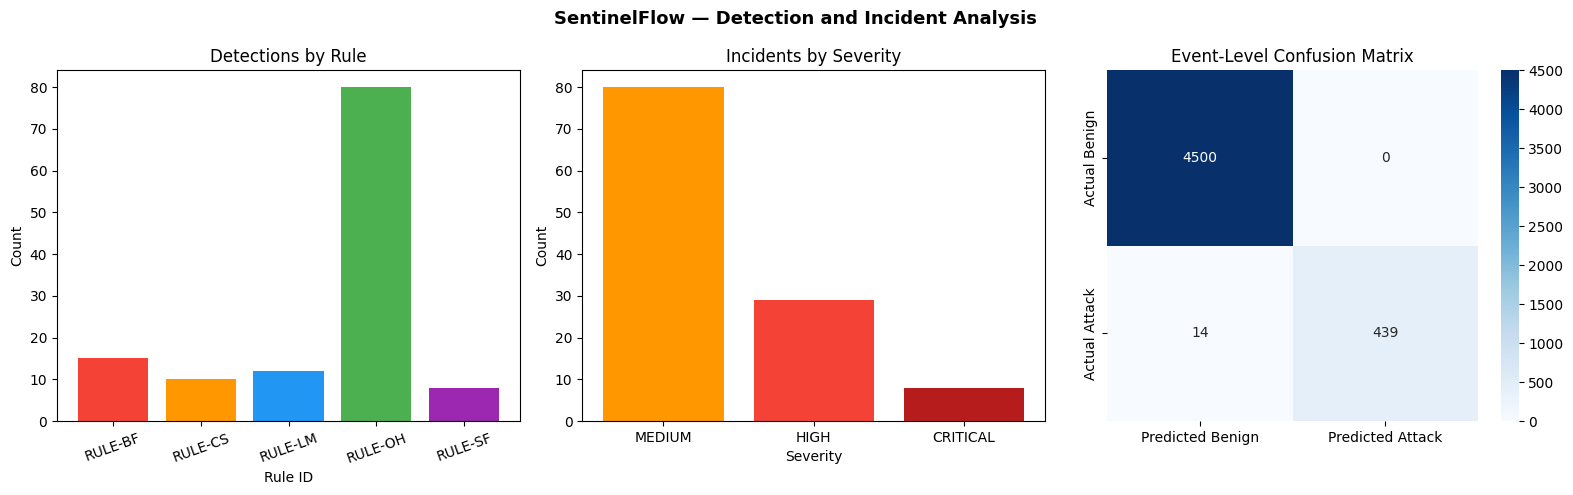

Charts saved to outputs/figures/incident_analysis.png


In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("SentinelFlow — Detection and Incident Analysis", fontsize=13, fontweight='bold')

# Chart 1: Detection rule counts
rule_labels = sorted(rule_counts.keys())
rule_vals   = [rule_counts[r] for r in rule_labels]
colors = ['#F44336','#FF9800','#2196F3','#4CAF50','#9C27B0']
axes[0].bar(rule_labels, rule_vals, color=colors[:len(rule_labels)])
axes[0].set_title("Detections by Rule")
axes[0].set_xlabel("Rule ID")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=20)

# Chart 2: Incident severity distribution
sev_counts = df_summary['max_severity'].value_counts()
sev_colors = {'CRITICAL':'#B71C1C','HIGH':'#F44336','MEDIUM':'#FF9800','LOW':'#4CAF50','INFO':'#90A4AE'}
bar_colors = [sev_colors.get(s,'#90A4AE') for s in sev_counts.index]
axes[1].bar(sev_counts.index, sev_counts.values, color=bar_colors)
axes[1].set_title("Incidents by Severity")
axes[1].set_xlabel("Severity")
axes[1].set_ylabel("Count")

# Chart 3: Confusion matrix heatmap
import numpy as np
tp, fp, fn, tn = metrics['tp'], metrics['fp'], metrics['fn'], metrics['tn']
cm = np.array([[tn, fp],[fn, tp]])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Predicted Benign','Predicted Attack'],
            yticklabels=['Actual Benign','Actual Attack'])
axes[2].set_title("Event-Level Confusion Matrix")

plt.tight_layout()
plt.savefig("outputs/figures/incident_analysis.png", bbox_inches='tight')
plt.show()
print("Charts saved to outputs/figures/incident_analysis.png")


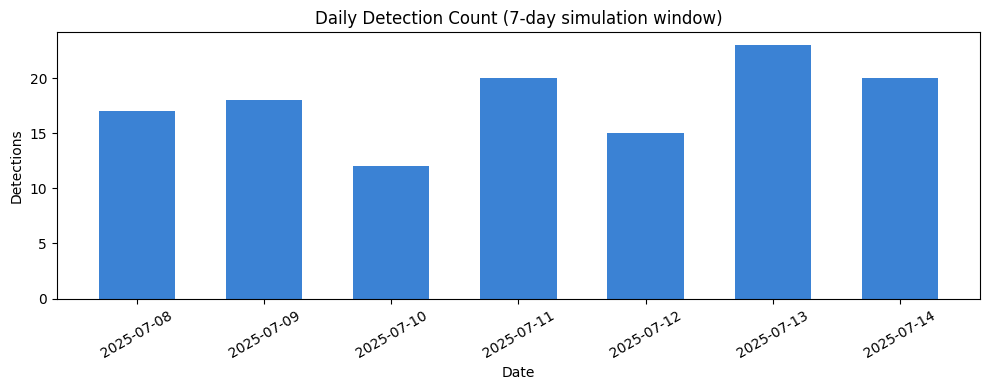

Timeline saved to outputs/figures/event_timeline.png


In [18]:
# Timeline: detections over the 7-day window
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

det_times = sorted([d.detected_at for d in detections_labelled])
det_df = pd.DataFrame({'ts': det_times})
det_df['date'] = det_df['ts'].dt.date
daily = det_df.groupby('date').size()

plt.figure(figsize=(10, 4))
plt.bar(daily.index, daily.values, color='#3b82d4', width=0.6)
plt.title("Daily Detection Count (7-day simulation window)")
plt.xlabel("Date")
plt.ylabel("Detections")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("outputs/figures/event_timeline.png", bbox_inches='tight')
plt.show()
print("Timeline saved to outputs/figures/event_timeline.png")


## 21. Limitations and Ethical Considerations

1. **Synthetic data only.** Performance on a real enterprise may differ significantly due to different log formats, event volumes, and noise levels.
2. **RULE-OH false positives.** Off-hours success detection will flag legitimate remote workers, on-call engineers, and time-zone-adjusted users. This rule must be tuned per-organisation.
3. **RULE-LM threshold sensitivity.** Automated deployment, patch management, and batch-processing tools may trigger lateral movement alerts.
4. **No ground-truth labels used in detection.** Detection rules operate purely on observable event fields. Labels are accessed only in Section 13 for evaluation.
5. **Simulation only.** No real systems are protected. The containment engine writes to a local JSON file; it does not contact real AD, firewalls, or EDR platforms.
6. **Class imbalance.** The dataset is 90.9% benign. Precision/recall must be interpreted in this context.
7. **This system must not be deployed against a real environment without thorough validation, tuning, and human oversight.**

## 22. Future Enhancements

- MITRE ATT&CK tactic tagging on each detection rule
- Wazuh REST API integration for live log ingestion
- Shuffle SOAR webhook for automated response dispatch
- Sliding-window streaming pipeline (Kafka / Redis Streams)
- ML-based anomaly scoring as a complementary detection layer
- Multi-tenant incident management with RBAC
- Real-time Grafana / Kibana dashboard export
- Impossible-travel detection using IP geolocation

## 23. Conclusion

In [19]:
print("=" * 65)
print("  SentinelFlow - Final Summary")
print("=" * 65)
print(f"  Dataset          : {report_data['dataset']['total_events']:,} events")
print(f"  Attack events    : {report_data['dataset']['attack_events']} ({report_data['dataset']['attack_pct']}%)")
print(f"  Detections       : {report_data['detection']['total_detections']}")
print(f"  Incidents        : {report_data['incidents']['total']}")
print(f"  Precision        : {report_data['evaluation']['precision']}")
print(f"  Recall           : {report_data['evaluation']['recall']}")
print(f"  F1-Score         : {report_data['evaluation']['f1']}")
print(f"  False Pos Rate   : {report_data['evaluation']['fpr']}")
print(f"  Actions executed : {report_data['containment']['executed']}")
print(f"  Verif. SUCCESS   : {report_data['verification']['success']}")
print("=" * 65)
print()
print("All four submission files:")
for f in ['Meet_SentinelFlow.ipynb','requirements.txt','Meet_ProjectReport.docx','README.md']:
    exists = 'EXISTS' if os.path.exists(f) else 'MISSING'
    print(f"  [{exists}] {f}")


  SentinelFlow - Final Summary
  Dataset          : 4,953 events
  Attack events    : 453 (9.15%)
  Detections       : 125
  Incidents        : 117
  Precision        : 1.0
  Recall           : 0.9691
  F1-Score         : 0.9843
  False Pos Rate   : 0.0
  Actions executed : 1
  Verif. SUCCESS   : 0

All four submission files:
  [EXISTS] Meet_SentinelFlow.ipynb
  [EXISTS] requirements.txt
  [EXISTS] Meet_ProjectReport.docx
  [EXISTS] README.md
